In [1]:
import sys, re, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import librosa
import matplotlib.pyplot as plt

from scipy.spatial.distance import cosine
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")

print("Python:", sys.executable)
print("Librosa:", librosa.__version__)


Python: /home/adminbum/ntqai/.venv/bin/python
Librosa: 1.0.0


/home/adminbum/ntqai/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
DATASET_PATH = Path("/mnt/d/Data/VNTM3")
AUDIT_CSV = DATASET_PATH / "_audit" / "audio_audit.csv"
OUTPUT_DIR = DATASET_PATH / "_source_boundary_v2"
OUTPUT_DIR.mkdir(exist_ok=True)

TARGET_SR = 22050
N_FFT = 2048
HOP = 512
N_MFCC = 20
N_CHROMA = 12


SEQ_STEPS = 64


BOUNDARY_SECONDS = 5.0

print("Audit:", AUDIT_CSV)
print("Output:", OUTPUT_DIR)

if not AUDIT_CSV.exists():
    raise FileNotFoundError(AUDIT_CSV)


Audit: /mnt/d/Data/VNTM3/_audit/audio_audit.csv
Output: /mnt/d/Data/VNTM3/_source_boundary_v2


In [3]:
df = pd.read_csv(AUDIT_CSV)
df = df[df["status"] == "OK"].copy()

df["exact_duplicate_removed"] = False
df["exact_duplicate_of"] = ""

for sha, part in df[df["sha256"].notna()].groupby("sha256"):
    if len(part) <= 1:
        continue
    part = part.sort_values(["label", "filename"])
    keeper = part.iloc[0]["relative_path"]
    for idx in part.index[1:]:
        df.loc[idx, "exact_duplicate_removed"] = True
        df.loc[idx, "exact_duplicate_of"] = keeper

removed = df[df["exact_duplicate_removed"]].copy()
work = df[~df["exact_duplicate_removed"]].copy()

def file_index(name):
    nums = re.findall(r"\d+", Path(name).stem)
    return int(nums[-1]) if nums else np.nan

work["file_index"] = work["filename"].apply(file_index)
work = work.sort_values(["label","file_index","filename"]).reset_index(drop=True)

print("Original OK files:", len(df))
print("Exact duplicate copies excluded:", len(removed))
print("Files investigated:", len(work))
display(work.groupby("label").size().rename("files").reset_index())


Original OK files: 2499
Exact duplicate copies excluded: 4
Files investigated: 2495


,label,files
0,cailuong,500
1,catru,496
2,chauvan,499
3,cheo,500
4,hatxam,500


In [4]:
def resize_time(mat, steps=64):
    
    if mat.shape[1] == steps:
        return mat.astype(np.float32)

    old_x = np.linspace(0, 1, mat.shape[1])
    new_x = np.linspace(0, 1, steps)

    out = np.vstack([
        np.interp(new_x, old_x, row)
        for row in mat
    ])
    return out.astype(np.float32)


def zscore_rows(mat):
    mu = mat.mean(axis=1, keepdims=True)
    sd = mat.std(axis=1, keepdims=True) + 1e-8
    return (mat - mu) / sd


def extract_features(path):
    y, _ = librosa.load(path, sr=TARGET_SR, mono=True)

    if len(y) == 0:
        raise ValueError("empty audio")

    y = y - np.mean(y)
    peak = np.max(np.abs(y))
    if peak > 1e-8:
        y = y / peak

    chroma = librosa.feature.chroma_stft(
        y=y, sr=TARGET_SR,
        n_fft=N_FFT, hop_length=HOP,
        n_chroma=N_CHROMA
    )

    mfcc = librosa.feature.mfcc(
        y=y, sr=TARGET_SR,
        n_mfcc=N_MFCC,
        n_fft=N_FFT,
        hop_length=HOP
    )

    centroid = librosa.feature.spectral_centroid(
        y=y, sr=TARGET_SR, n_fft=N_FFT, hop_length=HOP
    )
    bandwidth = librosa.feature.spectral_bandwidth(
        y=y, sr=TARGET_SR, n_fft=N_FFT, hop_length=HOP
    )
    rolloff = librosa.feature.spectral_rolloff(
        y=y, sr=TARGET_SR, n_fft=N_FFT, hop_length=HOP
    )
    zcr = librosa.feature.zero_crossing_rate(
        y, frame_length=N_FFT, hop_length=HOP
    )

    spectral = np.vstack([centroid, bandwidth, rolloff, zcr])

    edge_n = min(len(y), int(BOUNDARY_SECONDS * TARGET_SR))
    head = y[:edge_n]
    tail = y[-edge_n:]

    head_chroma = librosa.feature.chroma_stft(
        y=head, sr=TARGET_SR, n_fft=N_FFT, hop_length=HOP
    )
    tail_chroma = librosa.feature.chroma_stft(
        y=tail, sr=TARGET_SR, n_fft=N_FFT, hop_length=HOP
    )

    head_mfcc = librosa.feature.mfcc(
        y=head, sr=TARGET_SR, n_mfcc=N_MFCC,
        n_fft=N_FFT, hop_length=HOP
    )
    tail_mfcc = librosa.feature.mfcc(
        y=tail, sr=TARGET_SR, n_mfcc=N_MFCC,
        n_fft=N_FFT, hop_length=HOP
    )

    return {
        "chroma": resize_time(chroma, SEQ_STEPS),
        "mfcc": resize_time(zscore_rows(mfcc), SEQ_STEPS),
        "spectral_mean": np.array([
            np.mean(centroid),
            np.mean(bandwidth),
            np.mean(rolloff),
            np.mean(zcr)
        ], dtype=np.float32),
        "head_chroma": resize_time(head_chroma, 24),
        "tail_chroma": resize_time(tail_chroma, 24),
        "head_mfcc": resize_time(zscore_rows(head_mfcc), 24),
        "tail_mfcc": resize_time(zscore_rows(tail_mfcc), 24),
    }


def cosine_sim(a, b):
    a = np.ravel(a).astype(np.float64)
    b = np.ravel(b).astype(np.float64)

    na = np.linalg.norm(a)
    nb = np.linalg.norm(b)

    if na < 1e-10 or nb < 1e-10:
        return 0.0

    return float(np.dot(a, b) / (na * nb))


def shifted_sequence_similarity(A, B, max_shift=8):
    
    best = -1.0

    for shift in range(-max_shift, max_shift + 1):
        if shift < 0:
            a = A[:, -shift:]
            b = B[:, :B.shape[1] + shift]
        elif shift > 0:
            a = A[:, :A.shape[1] - shift]
            b = B[:, shift:]
        else:
            a, b = A, B

        if a.shape[1] < 8:
            continue

        s = cosine_sim(a, b)
        if s > best:
            best = s

    return best


In [5]:
CACHE_DIR = OUTPUT_DIR / "feature_cache"
CACHE_DIR.mkdir(exist_ok=True)

features = {}
errors = []

for row in tqdm(work.itertuples(index=False), total=len(work), desc="Features"):
    safe_name = row.relative_path.replace("/", "__").replace("\\", "__")
    cache_path = CACHE_DIR / f"{safe_name}.npz"

    try:
        if cache_path.exists():
            d = np.load(cache_path)
            feat = {k: d[k] for k in d.files}
        else:
            feat = extract_features(row.path)
            np.savez_compressed(cache_path, **feat)

        features[row.relative_path] = feat

    except Exception as e:
        errors.append({
            "label": row.label,
            "filename": row.filename,
            "relative_path": row.relative_path,
            "error": repr(e)
        })

errors_df = pd.DataFrame(errors)
print("Feature OK:", len(features))
print("Errors:", len(errors_df))

if len(errors_df):
    display(errors_df)


Features: 100%|██████████| 2495/2495 [09:52<00:00,  4.21it/s]

Feature OK: 2495
Errors: 0


In [6]:
records = []

for label, part in work.groupby("label"):
    part = part[pd.notna(part["file_index"])].sort_values("file_index")
    rows = list(part.itertuples(index=False))

    for a, b in tqdm(
        list(zip(rows[:-1], rows[1:])),
        desc=label,
        leave=False
    ):
        if int(b.file_index) - int(a.file_index) != 1:
            continue

        if a.relative_path not in features or b.relative_path not in features:
            continue

        fa = features[a.relative_path]
        fb = features[b.relative_path]

        chroma_seq = shifted_sequence_similarity(
            fa["chroma"], fb["chroma"], max_shift=8
        )
        mfcc_seq = shifted_sequence_similarity(
            fa["mfcc"], fb["mfcc"], max_shift=8
        )
        spectral = cosine_sim(
            fa["spectral_mean"], fb["spectral_mean"]
        )
        edge_chroma = shifted_sequence_similarity(
            fa["tail_chroma"], fb["head_chroma"], max_shift=5
        )
        edge_mfcc = shifted_sequence_similarity(
            fa["tail_mfcc"], fb["head_mfcc"], max_shift=5
        )

        records.append({
            "label": label,
            "file_a": a.filename,
            "file_b": b.filename,
            "path_a": a.relative_path,
            "path_b": b.relative_path,
            "index_a": int(a.file_index),
            "index_b": int(b.file_index),
            "chroma_seq": chroma_seq,
            "mfcc_seq": mfcc_seq,
            "spectral": spectral,
            "edge_chroma": edge_chroma,
            "edge_mfcc": edge_mfcc,
        })

pairs = pd.DataFrame(records)

print("Consecutive pairs:", len(pairs))
display(pairs.head())


Consecutive pairs: 2485


,label,file_a,file_b,path_a,path_b,index_a,index_b,chroma_seq,mfcc_seq,spectral,edge_chroma,edge_mfcc
0,cailuong,CaiLuong.000.wav,CaiLuong.001.wav,cailuong/CaiLuong.000.wav,cailuong/CaiLuong.001.wav,0,1,0.585876,0.041730,0.999823,0.676889,0.024541
1,cailuong,CaiLuong.001.wav,CaiLuong.002.wav,cailuong/CaiLuong.001.wav,cailuong/CaiLuong.002.wav,1,2,0.598607,0.087159,0.999849,0.529675,0.239208
2,cailuong,CaiLuong.002.wav,CaiLuong.003.wav,cailuong/CaiLuong.002.wav,cailuong/CaiLuong.003.wav,2,3,0.580642,0.075767,0.999717,0.528410,0.038840
3,cailuong,CaiLuong.003.wav,CaiLuong.004.wav,cailuong/CaiLuong.003.wav,cailuong/CaiLuong.004.wav,3,4,0.616726,0.008323,0.999949,0.596526,0.030488
4,cailuong,CaiLuong.004.wav,CaiLuong.005.wav,cailuong/CaiLuong.004.wav,cailuong/CaiLuong.005.wav,4,5,0.591225,0.063341,0.999811,0.724874,0.098235


In [7]:
metric_cols = [
    "chroma_seq",
    "mfcc_seq",
    "spectral",
    "edge_chroma",
    "edge_mfcc"
]

scored_parts = []

for label, part in pairs.groupby("label"):
    p = part.copy()

    for col in metric_cols:
        p[col + "_pct"] = p[col].rank(pct=True, method="average")

    
    p["continuity_score"] = (
        0.20 * p["chroma_seq_pct"] +
        0.15 * p["mfcc_seq_pct"] +
        0.10 * p["spectral_pct"] +
        0.30 * p["edge_chroma_pct"] +
        0.25 * p["edge_mfcc_pct"]
    )

    scored_parts.append(p)

scored = pd.concat(scored_parts, ignore_index=True)




scored["boundary_candidate"] = "no"

for label, idx in scored.groupby("label").groups.items():
    vals = scored.loc[idx, "continuity_score"]
    q05 = vals.quantile(0.05)
    q10 = vals.quantile(0.10)

    scored.loc[
        (scored["label"] == label) &
        (scored["continuity_score"] <= q10),
        "boundary_candidate"
    ] = "review"

    scored.loc[
        (scored["label"] == label) &
        (scored["continuity_score"] <= q05),
        "boundary_candidate"
    ] = "strong"

display(
    scored.sort_values(
        ["label", "continuity_score"]
    ).head(30)
)


,label,file_a,file_b,path_a,path_b,index_a,index_b,chroma_seq,mfcc_seq,spectral,edge_chroma,edge_mfcc,chroma_seq_pct,mfcc_seq_pct,spectral_pct,edge_chroma_pct,edge_mfcc_pct,continuity_score,boundary_candidate
444,cailuong,CaiLuong.444.wav,CaiLuong.445.wav,cailuong/CaiLuong.444.wav,cailuong/CaiLuong.445.wav,444,445,0.441239,0.022934,0.996221,0.431327,0.038055,0.028056,0.082164,0.026052,0.040080,0.128257,0.064629,strong
495,cailuong,CaiLuong.495.wav,CaiLuong.496.wav,cailuong/CaiLuong.495.wav,cailuong/CaiLuong.496.wav,495,496,0.441442,0.024919,0.999011,0.392305,0.032558,0.032064,0.102204,0.158317,0.020040,0.094188,0.067134,strong
368,cailuong,CaiLuong.368.wav,CaiLuong.369.wav,cailuong/CaiLuong.368.wav,cailuong/CaiLuong.369.wav,368,369,0.474380,0.028369,0.999322,0.479430,0.007024,0.102204,0.116232,0.206413,0.118236,0.028056,0.101002,strong
421,cailuong,CaiLuong.421.wav,CaiLuong.422.wav,cailuong/CaiLuong.421.wav,cailuong/CaiLuong.422.wav,421,422,0.453712,0.039540,0.995673,0.416191,0.062239,0.046092,0.216433,0.018036,0.032064,0.274549,0.121743,strong
318,cailuong,CaiLuong.318.wav,CaiLuong.319.wav,cailuong/CaiLuong.318.wav,cailuong/CaiLuong.319.wav,318,319,0.464227,0.050902,0.996612,0.369750,0.063533,0.076152,0.384770,0.034068,0.012024,0.284569,0.151102,strong
459,cailuong,CaiLuong.459.wav,CaiLuong.460.wav,cailuong/CaiLuong.459.wav,cailuong/CaiLuong.460.wav,459,460,0.375963,0.081696,0.998988,0.296975,0.029275,0.002004,0.785571,0.154309,0.004008,0.074148,0.153407,strong
456,cailuong,CaiLuong.456.wav,CaiLuong.457.wav,cailuong/CaiLuong.456.wav,cailuong/CaiLuong.457.wav,456,457,0.494798,0.054789,0.997370,0.454797,0.036598,0.178357,0.438878,0.048096,0.064128,0.112224,0.153607,strong
367,cailuong,CaiLuong.367.wav,CaiLuong.368.wav,cailuong/CaiLuong.367.wav,cailuong/CaiLuong.368.wav,367,368,0.476736,0.012044,0.998997,0.469454,0.072634,0.108216,0.044088,0.156313,0.086172,0.342685,0.155411,strong
220,cailuong,CaiLuong.220.wav,CaiLuong.221.wav,cailuong/CaiLuong.220.wav,cailuong/CaiLuong.221.wav,220,221,0.470939,0.031360,0.999303,0.515019,0.033386,0.090180,0.148297,0.204409,0.246493,0.098196,0.159218,strong
165,cailuong,CaiLuong.165.wav,CaiLuong.166.wav,cailuong/CaiLuong.165.wav,cailuong/CaiLuong.166.wav,165,166,0.516454,0.034774,0.999098,0.491629,0.005752,0.350701,0.166333,0.170341,0.150301,0.022044,0.162725,strong


In [8]:
summary = (
    scored.groupby(["label", "boundary_candidate"])
    .size()
    .unstack(fill_value=0)
)

display(summary)

candidates = scored[
    scored["boundary_candidate"] != "no"
].copy().sort_values(
    ["label", "continuity_score"]
)

print("Total candidate boundaries:", len(candidates))
display(
    candidates[
        [
            "label","file_a","file_b",
            "continuity_score","boundary_candidate",
            "chroma_seq","mfcc_seq","spectral",
            "edge_chroma","edge_mfcc"
        ]
    ].head(100)
)


boundary_candidate,no,review,strong
label,,,
cailuong,449,25,25
catru,441,25,25
chauvan,447,25,25
cheo,449,25,25
hatxam,449,25,25


Total candidate boundaries: 250


,label,file_a,file_b,continuity_score,boundary_candidate,chroma_seq,mfcc_seq,spectral,edge_chroma,edge_mfcc
444,cailuong,CaiLuong.444.wav,CaiLuong.445.wav,0.064629,strong,0.441239,0.022934,0.996221,0.431327,0.038055
495,cailuong,CaiLuong.495.wav,CaiLuong.496.wav,0.067134,strong,0.441442,0.024919,0.999011,0.392305,0.032558
368,cailuong,CaiLuong.368.wav,CaiLuong.369.wav,0.101002,strong,0.474380,0.028369,0.999322,0.479430,0.007024
421,cailuong,CaiLuong.421.wav,CaiLuong.422.wav,0.121743,strong,0.453712,0.039540,0.995673,0.416191,0.062239
318,cailuong,CaiLuong.318.wav,CaiLuong.319.wav,0.151102,strong,0.464227,0.050902,0.996612,0.369750,0.063533
...,...,...,...,...,...,...,...,...,...,...
784,catru,Catru.287.wav,Catru.288.wav,0.268534,review,0.423192,0.060832,0.998567,0.327559,0.112907
566,catru,Catru.067.wav,Catru.068.wav,0.270468,review,0.449277,-0.071104,0.999988,0.470491,0.010091
750,catru,Catru.253.wav,Catru.254.wav,0.276069,review,0.430801,0.017423,0.995605,0.459013,0.100481
913,catru,Catru.418.wav,Catru.419.wav,0.276578,review,0.424964,0.028107,0.999727,0.516335,-0.031771


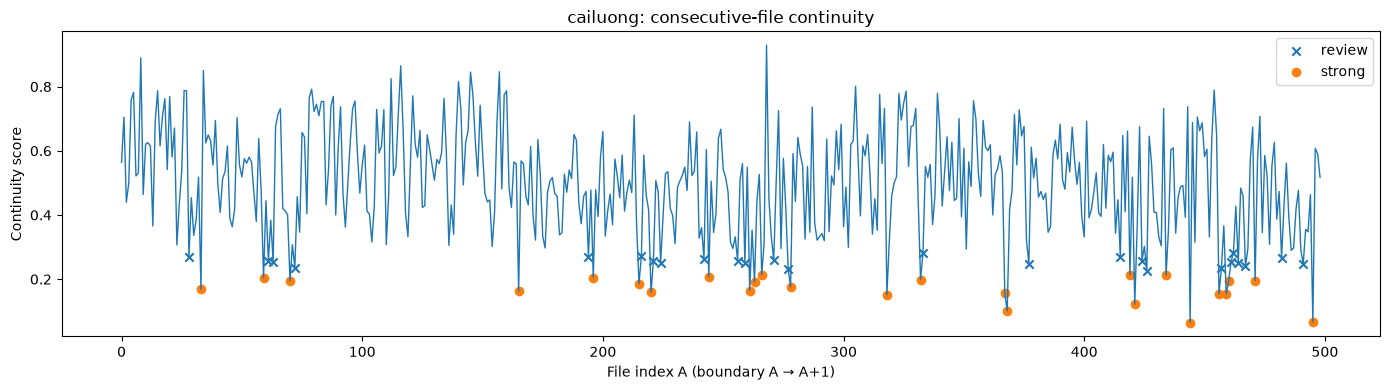

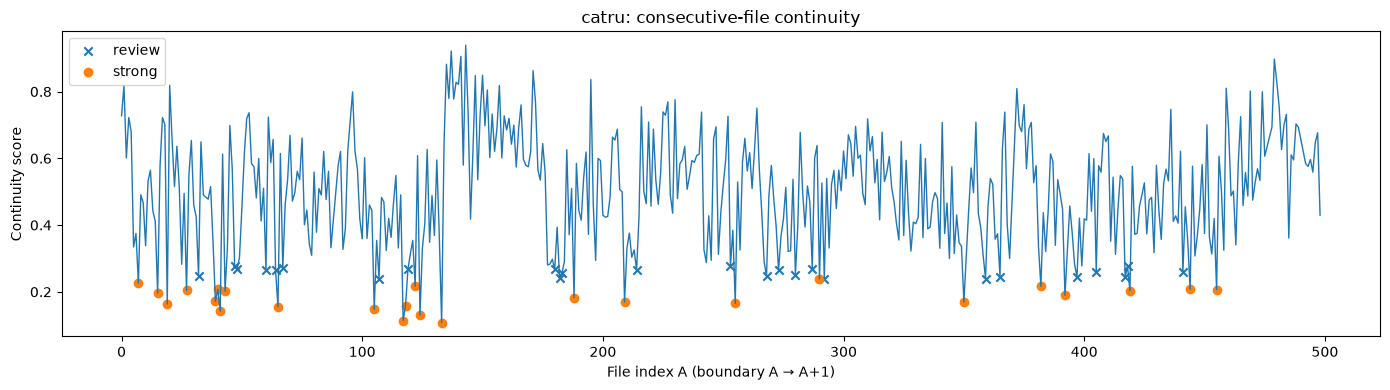

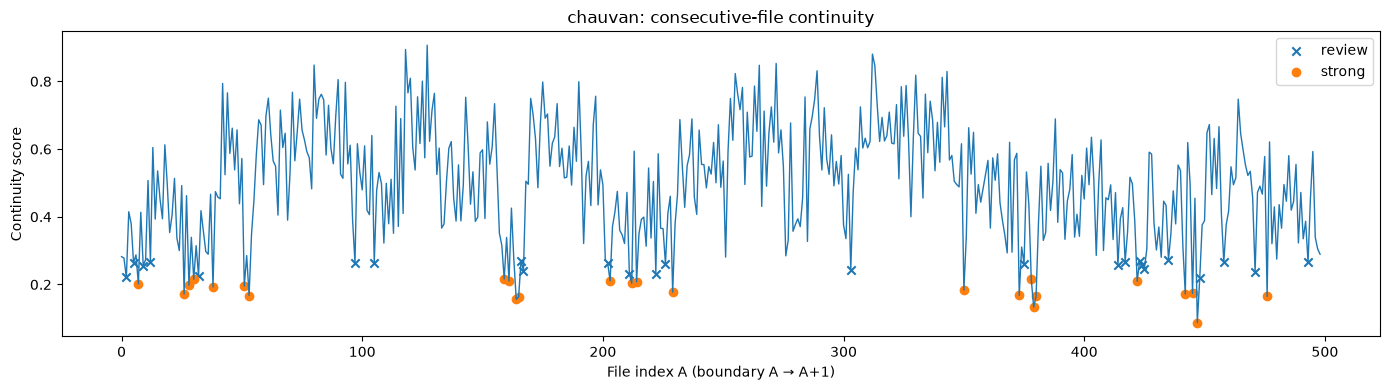

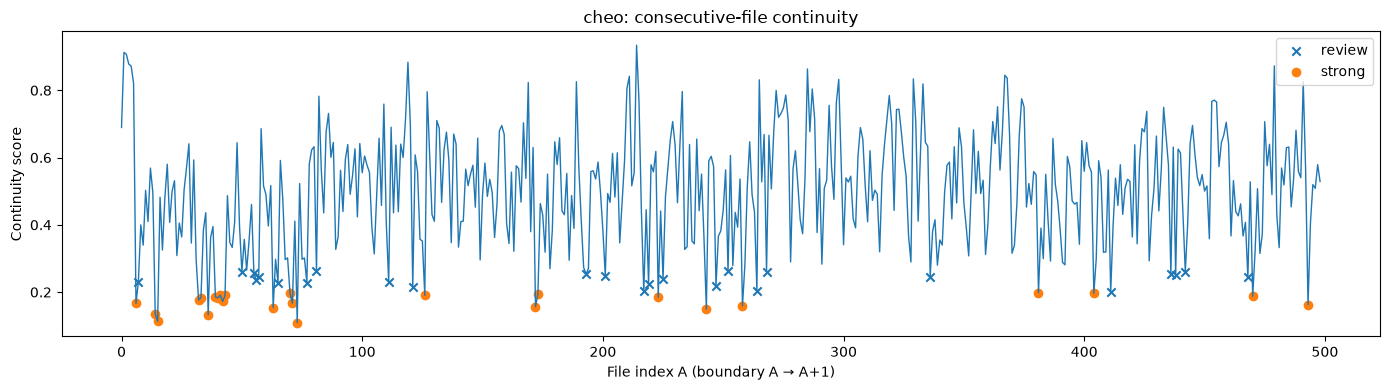

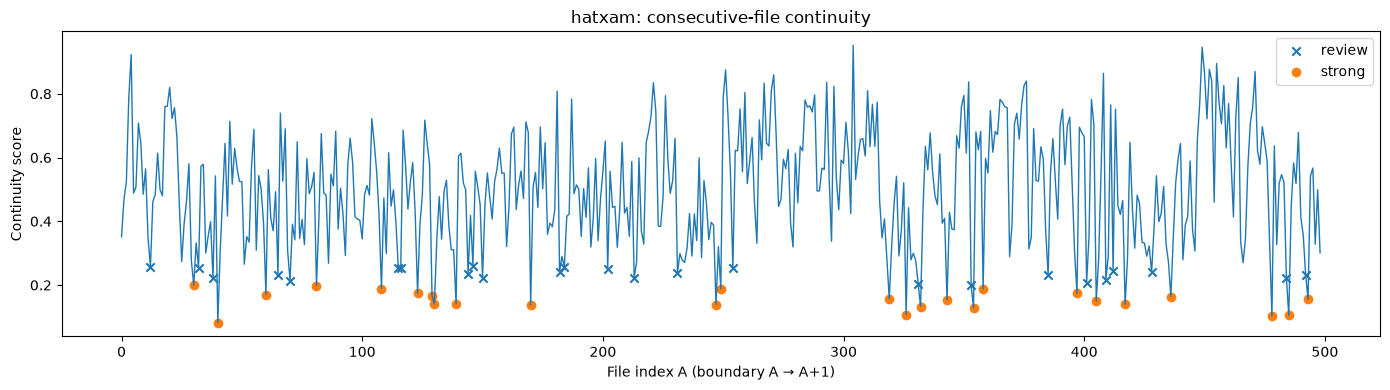

In [9]:
for label, part in scored.groupby("label"):
    part = part.sort_values("index_a")

    plt.figure(figsize=(14, 4))
    plt.plot(
        part["index_a"],
        part["continuity_score"],
        linewidth=1
    )

    strong = part[part["boundary_candidate"] == "strong"]
    review = part[part["boundary_candidate"] == "review"]

    if len(review):
        plt.scatter(
            review["index_a"],
            review["continuity_score"],
            marker="x",
            label="review"
        )

    if len(strong):
        plt.scatter(
            strong["index_a"],
            strong["continuity_score"],
            marker="o",
            label="strong"
        )

    plt.xlabel("File index A (boundary A → A+1)")
    plt.ylabel("Continuity score")
    plt.title(f"{label}: consecutive-file continuity")
    plt.legend()
    plt.tight_layout()
    plt.show()


In [10]:
provisional_rows = []

for label, part in work.groupby("label"):
    part = part[pd.notna(part["file_index"])].sort_values("file_index").copy()

    boundary_lookup = {
        int(r.index_b): r.boundary_candidate
        for r in scored[scored["label"] == label].itertuples(index=False)
    }

    group_num = 1

    for row in part.itertuples(index=False):
        idx = int(row.file_index)

        
        if boundary_lookup.get(idx) == "strong":
            group_num += 1

        provisional_rows.append({
            "label": label,
            "filename": row.filename,
            "relative_path": row.relative_path,
            "file_index": idx,
            "provisional_group": f"{label}_P{group_num:03d}"
        })

provisional = pd.DataFrame(provisional_rows)

group_sizes = (
    provisional.groupby(["label","provisional_group"])
    .size()
    .rename("n_files")
    .reset_index()
)

display(
    group_sizes.groupby("label")["n_files"]
    .agg(["count","mean","median","min","max"])
    .round(2)
)

print("IMPORTANT: provisional groups are NOT final split groups.")


,count,mean,median,min,max
label,,,,,
cailuong,26,19.23,12.5,1,95
catru,26,19.08,11.5,1,60
chauvan,26,19.19,8.0,1,121
cheo,26,19.23,7.0,1,123
hatxam,26,19.23,11.0,1,77


IMPORTANT: provisional groups are NOT final split groups.


In [11]:
scored.to_csv(
    OUTPUT_DIR / "consecutive_similarity_all.csv",
    index=False, encoding="utf-8-sig"
)

candidates.to_csv(
    OUTPUT_DIR / "boundary_candidates.csv",
    index=False, encoding="utf-8-sig"
)

provisional.to_csv(
    OUTPUT_DIR / "provisional_groups.csv",
    index=False, encoding="utf-8-sig"
)

group_sizes.to_csv(
    OUTPUT_DIR / "provisional_group_sizes.csv",
    index=False, encoding="utf-8-sig"
)

errors_df.to_csv(
    OUTPUT_DIR / "feature_errors.csv",
    index=False, encoding="utf-8-sig"
)

removed.to_csv(
    OUTPUT_DIR / "exact_duplicates_removed.csv",
    index=False, encoding="utf-8-sig"
)

print("Saved to:", OUTPUT_DIR)
for p in sorted(OUTPUT_DIR.glob("*.csv")):
    print(" -", p.name)


Saved to: /mnt/d/Data/VNTM3/_source_boundary_v2
 - boundary_candidates.csv
 - consecutive_similarity_all.csv
 - exact_duplicates_removed.csv
 - feature_errors.csv
 - provisional_group_sizes.csv
 - provisional_groups.csv


In [12]:
print("="*70)
print("SOURCE BOUNDARY V2 REPORT")
print("="*70)
print("Audio investigated      :", len(work))
print("Consecutive pairs       :", len(scored))
print("Strong candidates       :", int((scored["boundary_candidate"]=="strong").sum()))
print("Review candidates       :", int((scored["boundary_candidate"]=="review").sum()))
print("Feature errors          :", len(errors_df))
print("Exact copies excluded   :", len(removed))
print("\nDo NOT train yet. Send the generated CSV reports for review.")


SOURCE BOUNDARY V2 REPORT
Audio investigated      : 2495
Consecutive pairs       : 2485
Strong candidates       : 125
Review candidates       : 125
Feature errors          : 0
Exact copies excluded   : 4

Do NOT train yet. Send the generated CSV reports for review.
